<a href="https://colab.research.google.com/github/hsb-ctrl-zy/multi-team1-project/blob/main/%EC%BD%94%EB%9E%A9/%EB%B3%B8%EB%AC%B8_%EA%B8%80%EC%9E%90_%EC%88%98.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 필요 라이브러리 설치 및 로드

In [ ]:
!pip install pymysql

In [ ]:
import pymysql

### SQL 연결

In [ ]:
#데이터베이스 연결
conn=pymysql.connect(
    host=host_name,
    user=user_name,
    password=password_val,
    database=db_name,
    port=port_num,
    charset='utf8'
)

### MySQL 연결 상태 확인

In [ ]:
if conn:
    try:
        # 커서를 생성하여 쿼리 실행 준비
        with conn.cursor() as cursor:
            # 간단한 쿼리로 현재 연결된 데이터베이스 이름을 확인
            cursor.execute("SELECT DATABASE();")
            result = cursor.fetchone()
            if result and result[0]:
                print(f"데이터베이스 연결이 성공적으로 확인되었습니다. 현재 데이터베이스: {result[0]}")
            else:
                print("데이터베이스에 연결되었지만, 현재 데이터베이스 이름을 가져올 수 없습니다.")
    except pymysql.Error as e:
        print(f"데이터베이스 연결 확인 중 오류 발생: {e}")
        print("연결에 문제가 있을 수 있습니다.")
else:
    print("데이터베이스 연결 객체(conn)가 생성되지 않았습니다. 연결이 실패했을 수 있습니다.")

데이터베이스 연결이 성공적으로 확인되었습니다. 현재 데이터베이스: geo_db


### `text_contents` 글자 수 분석

In [ ]:
import pandas as pd

try:
    with conn.cursor() as cursor:
        sql_query = "SELECT text_contents FROM raw_data_table;"
        cursor.execute(sql_query)

        all_contents = cursor.fetchall()

        # 결과를 DataFrame으로 변환
        df_contents = pd.DataFrame(all_contents, columns=['text_contents'])

        print(f"총 {len(df_contents)}개의 텍스트를 가져왔습니다.")

except pymysql.Error as e:
    print(f"데이터베이스 쿼리 실행 중 오류 발생: {e}")
except Exception as e:
    print(f"예상치 못한 오류 발생: {e}")


총 8763개의 텍스트를 가져왔습니다.


In [ ]:
# text_contents의 글자 수 계산 (NaN 값은 0으로 처리하거나 제외)
df_contents['text_length'] = df_contents['text_contents'].apply(lambda x: len(str(x)) if x is not None else 0)

# 각 행의 text_contents와 글자 수 출력
print("각 행의 텍스트 내용과 글자 수:")
display(df_contents[['text_contents', 'text_length']].head())

# 전체 글자 수에 대한 기술 통계량 (원래 코드)
print("\n텍스트 글자 수에 대한 기술 통계량:")
display(df_contents['text_length'].describe())

각 행의 텍스트 내용과 글자 수:


,text_contents,text_length
0,,0
1,[엔비에이][NBA] 스몰로고 트레이닝 반바지(N262TP942P)\n시그니처 로고...,1090
2,,0
3,,0
4,,0



텍스트 글자 수에 대한 기술 통계량:


,text_length
count,8763.000000
mean,269.940203
std,582.533216
min,0.000000
25%,0.000000
50%,6.000000
75%,428.000000
max,4238.000000


In [ ]:
try:
    with conn.cursor() as cursor:
        sql_query_brand = "SELECT text_contents, brand_type FROM raw_data_table;"
        cursor.execute(sql_query_brand)

        all_data_with_brand = cursor.fetchall()

        # 결과를 DataFrame으로 변환
        df_with_brand = pd.DataFrame(all_data_with_brand, columns=['text_contents', 'brand_type'])

        print(f"총 {len(df_with_brand)}개의 텍스트와 브랜드 타입 데이터를 가져왔습니다.")

except pymysql.Error as e:
    print(f"데이터베이스 쿼리 실행 중 오류 발생: {e}")
except Exception as e:
    print(f"예상치 못한 오류 발생: {e}")


총 8763개의 텍스트와 브랜드 타입 데이터를 가져왔습니다.


In [ ]:
# text_contents의 글자 수 계산 (NaN 값은 0으로 처리하거나 제외)
df_with_brand['text_length'] = df_with_brand['text_contents'].apply(lambda x: len(str(x)) if x is not None else 0)

# brand_type별 평균 글자 수 분석
print("\nBrand Type별 텍스트 글자 수 평균:")
display(df_with_brand.groupby('brand_type')['text_length'].mean().reset_index())



Brand Type별 텍스트 글자 수 평균:


,brand_type,text_length
0,대기업,197.197739
1,소상공인,408.761699


In [ ]:
from google.colab import files
files.upload()

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 마이너스 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# --- 사용자 제공 폰트 설정 ---
font_path = '/content/Pretendard－M.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
    print(f"'{font_name}' 폰트 설정 완료.")
else:
    print(f"경로에 '{font_path}' 폰트 파일을 찾을 수 없습니다. 기본 폰트(나눔고딕 또는 대체 폰트)를 사용합니다.")
    try:
        fm.findfont('NanumGothic', rebuild_if_missing=True)
        plt.rc('font', family='NanumGothic')
        print("NanumGothic 폰트가 설치되어 있어 이를 사용합니다.")
    except Exception:
        plt.rc('font', family='DejaVu Sans')
        print("기본 폰트를 찾을 수 없어 'DejaVu Sans'를 사용합니다.")

# 모든 텍스트 및 축 요소 색상을 흰색으로 설정
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'
plt.rcParams['axes.edgecolor'] = 'white'
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'

print("Matplotlib 한글 폰트 및 디자인 설정 완료 (Pretendard 폰트 파일을 업로드해야 제대로 적용됩니다).")

'Pretendard' 폰트 설정 완료.
Matplotlib 한글 폰트 및 디자인 설정 완료 (Pretendard 폰트 파일을 업로드해야 제대로 적용됩니다).


### 데이터 행 수에 따른 텍스트 글자 수 산점도

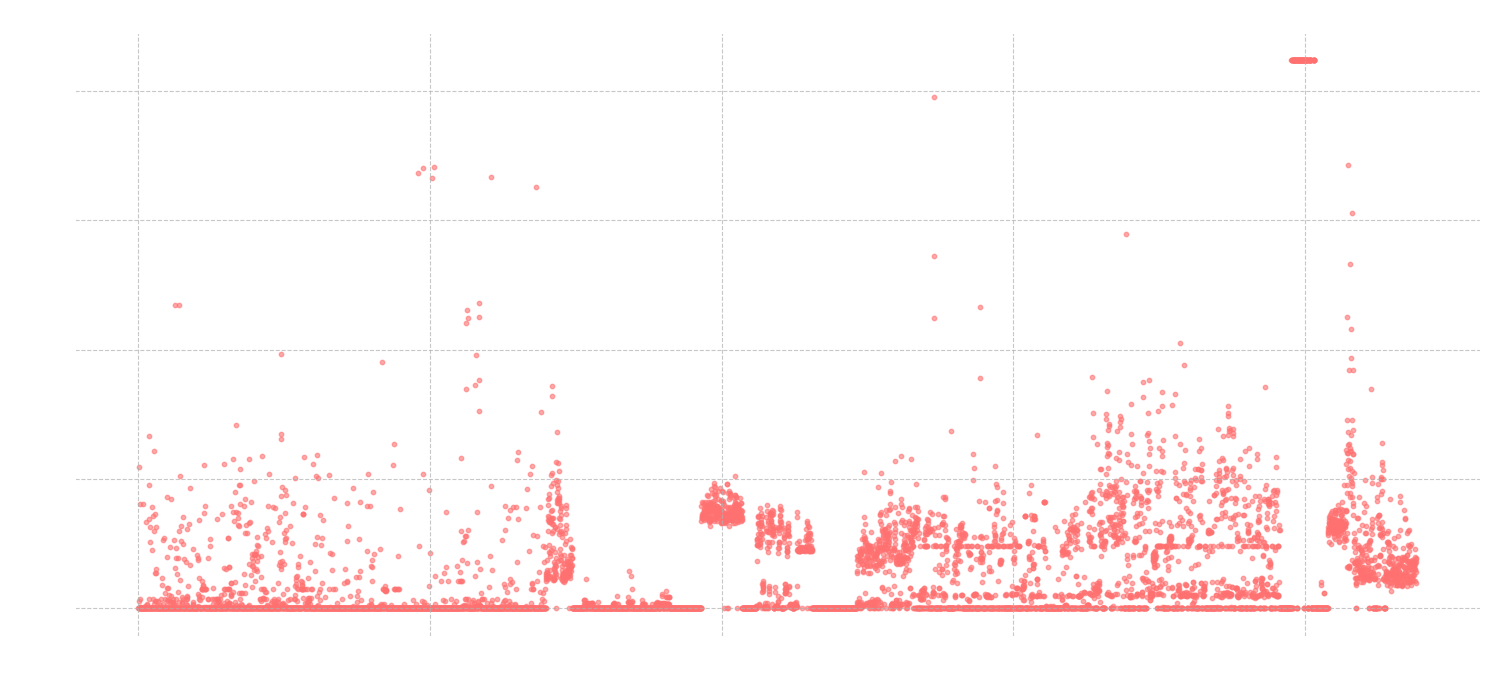

In [ ]:
# 데이터 행 수(인덱스)와 글자 수를 이용한 산점도 그래프 시각화
fig = plt.figure(figsize=(15, 7))
plt.scatter(df_contents.index, df_contents['text_length'], alpha=0.6, s=10, color='#FF7171')

plt.title('데이터 행 번호에 따른 텍스트 글자 수', fontsize=15)
plt.xlabel('데이터 행 번호', fontsize=12)
plt.ylabel('글자 수', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('본문 텍스트 글자 수(scat).png')

plt.show()

### 데이터 행 수에 따른 텍스트 글자 수 히스토그램

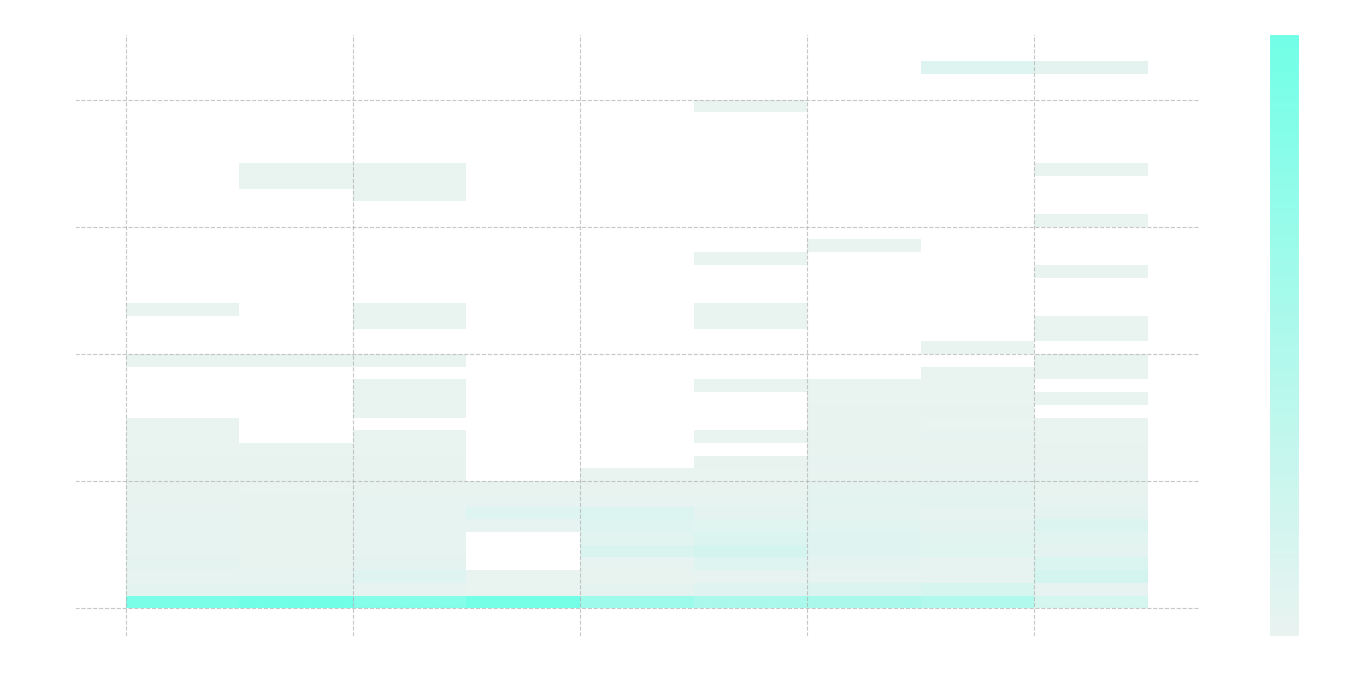

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(15, 7))
ax = sns.histplot(
    data=df_contents,
    x=df_contents.index,
    y='text_length',
    binwidth=(1000, 100),
    cmap=sns.light_palette("#71FFE7", as_cmap=True),
    cbar=True,
    cbar_kws={'label': '빈도수'}
)

plt.title('데이터 행 번호에 따른 텍스트 글자 수 분포 (2D 히스토그램)', fontsize=15)
plt.xlabel('데이터 행 번호', fontsize=12)
plt.ylabel('글자 수', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# 컬러바 레이블 및 틱 색상 설정 (rcParams에 의해 자동으로 적용되나 명시적으로 설정)
cbar = ax.collections[0].colorbar
cbar.set_label('빈도수', color='white')
cbar.ax.yaxis.set_tick_params(colors='white')

plt.tight_layout()
plt.savefig('본문 텍스트 글자 수(hist)_2d.png')

plt.show()

### 대기업 vs 소상공인 텍스트 글자 수 비교

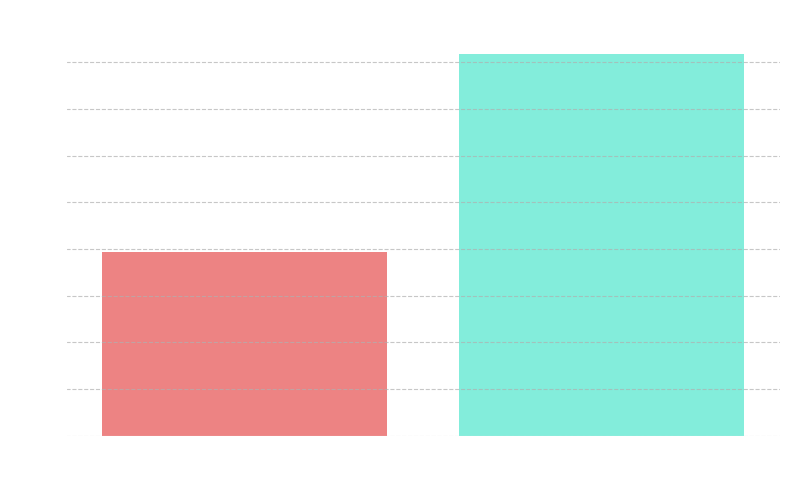

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# brand_type별 평균 글자 수 계산
avg_text_length_by_brand = df_with_brand.groupby('brand_type')['text_length'].mean().reset_index()

# 커스텀 팔레트 설정
color_map = {'대기업': '#FF7171', '소상공인': '#71FFE7'}

# 막대 그래프 시각화
fig = plt.figure(figsize=(8, 5))
ax = sns.barplot(x='brand_type', y='text_length', data=avg_text_length_by_brand, hue='brand_type', palette=color_map, legend=False)

plt.title('Brand Type별 평균 텍스트 글자 수', fontsize=15)
plt.xlabel('Brand Type', fontsize=12)
plt.ylabel('평균 글자 수', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 막대 위에 수치 표시
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.1f}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, color='white', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.savefig('brand_type별_평균글자수.png')


plt.show()

In [ ]:
# 1. DB에서 브랜드명, brand_type, text_contents를 함께 가져오기
try:
    with conn.cursor() as cursor:
        sql_query_brand_detail = "SELECT text_contents, brand_type, brand_name FROM raw_data_table;"
        cursor.execute(sql_query_brand_detail)
        all_data_brand_detail = cursor.fetchall()

        # 새로운 DataFrame 생성
        df_brand_detail = pd.DataFrame(all_data_brand_detail, columns=['text_contents', 'brand_type', 'brand_name'])
        print(f"총 {len(df_brand_detail)}개의 데이터를 성공적으로 가져왔습니다.")
except Exception as e:
    print(f"오류 발생: {e}")

# 2. 글자 수 계산
df_brand_detail['text_length'] = df_brand_detail['text_contents'].apply(
    lambda x: len(str(x)) if x is not None else 0
)

총 8763개의 데이터를 성공적으로 가져왔습니다.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 브랜드별 평균 글자 수 계산
avg_by_brand_all = df_brand_detail.groupby(['brand_name', 'brand_type'])['text_length'].mean().reset_index()

# 대기업 / 소상공인 데이터 분리 및 정렬
df_major = avg_by_brand_all[avg_by_brand_all['brand_type'] == '대기업'].sort_values(by='text_length', ascending=False)
df_small = avg_by_brand_all[avg_by_brand_all['brand_type'] == '소상공인'].sort_values(by='text_length', ascending=False)

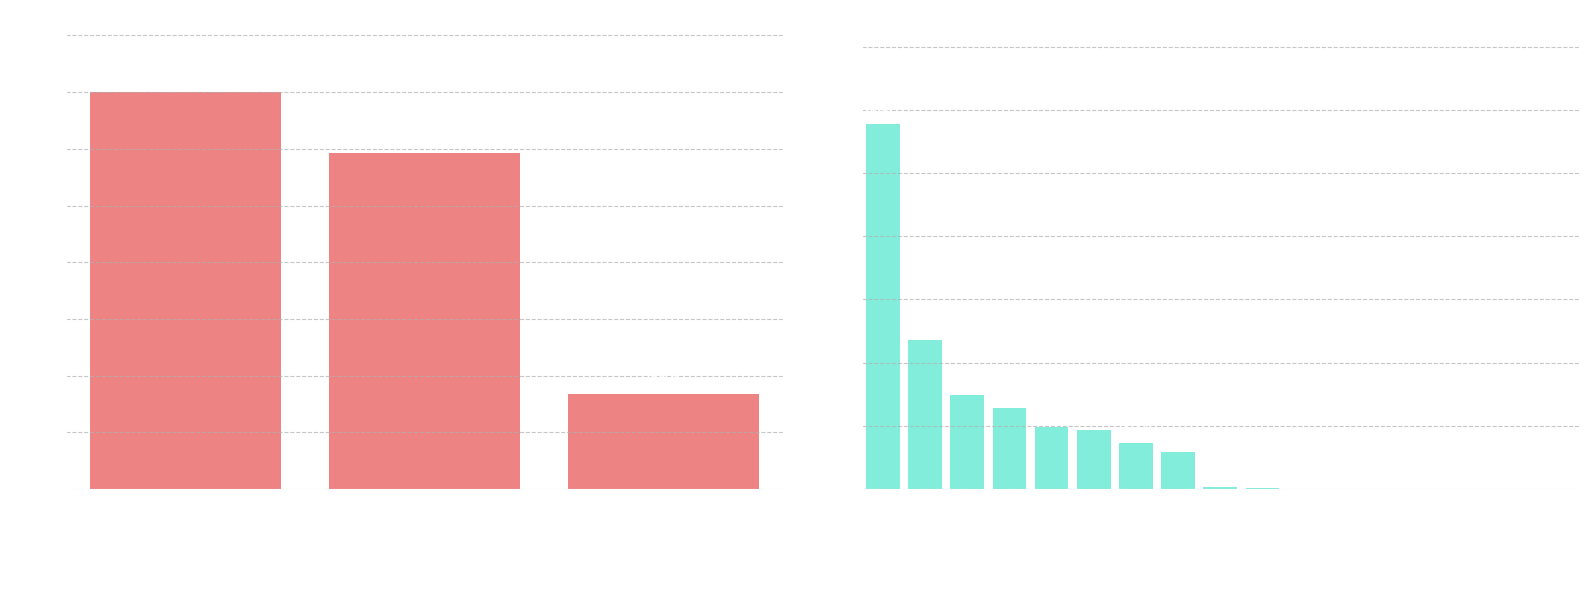

In [ ]:
# 2. 1행 2열 구조의 서브플롯 생성
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# [좌측] 대기업 차트
sns.barplot(
    data=df_major,
    x='brand_name',
    y='text_length',
    ax=axes[0],
    color='#FF7171'
)
axes[0].set_title(f'대기업 브랜드별 평균 글자 수 (총 {len(df_major)}개)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('브랜드명', fontsize=12)
axes[0].set_ylabel('평균 글자 수', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# 대기업 막대 위 수치 표시
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{height:.1f}',
                         (p.get_x() + p.get_width() / 2., height),
                         ha='center', va='bottom', fontsize=10, fontweight='bold', color='white', xytext=(0, 3),
                         textcoords='offset points')

# [우측] 소상공인 차트
sns.barplot(
    data=df_small,
    x='brand_name',
    y='text_length',
    ax=axes[1],
    color='#71FFE7'
)
axes[1].set_title(f'소상공인 브랜드별 평균 글자 수 (총 {len(df_small)}개)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('브랜드명', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# 소상공인 막대 위 수치 표시
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(f'{height:.1f}',
                         (p.get_x() + p.get_width() / 2., height),
                         ha='center', va='bottom', fontsize=9, rotation=0, color='white', xytext=(0, 5),
                         textcoords='offset points')

# 여백 조절
axes[0].set_ylim(0, df_major['text_length'].max() * 1.15)
axes[1].set_ylim(0, df_small['text_length'].max() * 1.25)

plt.tight_layout()

plt.savefig('브랜드별_텍스트_비교.png')
plt.show()

### 교정 전/후 본문 텍스트 분량 차이 검정 (이미지 텍스트 X)
- 교정 전(raw_data) 교정 후 (geo_correction_table)
- paired-t검정 / 윌콕슨 부호순위 검정 / 정규성 검정
- (or 비모수 검정)

검정 전: 데이터 준비 (DB 조회 및 글자 수 계산)

In [ ]:
# geo_correction_table의 컬럼 목록 확인
try:
    with conn.cursor() as cursor:
        cursor.execute("DESCRIBE geo_correction_table;")
        columns = cursor.fetchall()
        print("=== geo_correction_table 컬럼 목록 ===")
        for col in columns:
            print(f"- {col[0]} ({col[1]})")
except Exception as e:
    print(f"컬럼 정보 조회 실패: {e}")

=== geo_correction_table 컬럼 목록 ===
- correction_id (int)
- page_id (int)
- cor_sys_prompt_ver (varchar(32))
- corrected_title (varchar(255))
- corrected_body (text)
- recommended_alt_list (text)
- json_ld_code (text)
- recommended_faq_list (text)


In [ ]:
# raw_data_table 컬럼 목록 확인
try:
    with conn.cursor() as cursor:
        cursor.execute("DESCRIBE raw_data_table;")
        columns = cursor.fetchall()
        print("=== raw_data_table 컬럼 목록 ===")
        for col in columns:
            print(f"- {col[0]} ({col[1]})")
except Exception as e:
    print(f"컬럼 정보 조회 실패: {e}")

=== raw_data_table 컬럼 목록 ===
- page_id (int)
- brand_name (varchar(255))
- brand_type (varchar(32))
- product_name (varchar(255))
- product_cat (varchar(255))
- text_contents (text)
- image_text (longtext)
- has_json_ld (tinyint(1))
- json_ld_contents (longtext)


In [ ]:
import pandas as pd
import numpy as np

# 두 테이블의 컬럼명 지정
CORRECTED_COLUMN_NAME = "corrected_body"
RAW_PK_NAME = "page_id"

try:
    with conn.cursor() as cursor:
        sql = f"""
        SELECT
            r.text_contents AS raw_text,
            c.{CORRECTED_COLUMN_NAME} AS corrected_text
        FROM raw_data_table r
        JOIN geo_correction_table c ON r.{RAW_PK_NAME} = c.page_id;
        """
        cursor.execute(sql)
        data = cursor.fetchall()
        df = pd.DataFrame(data, columns=['raw_text', 'corrected_text'])

    # 글자 수 계산 (None 값은 0 처리)
    df['raw_length'] = df['raw_text'].apply(lambda x: len(str(x)) if x is not None else 0)
    df['corrected_length'] = df['corrected_text'].apply(lambda x: len(str(x)) if x is not None else 0)

    # 글자 수 차이 계산 (교정 후 - 교정 전)
    df['diff'] = df['corrected_length'] - df['raw_length']

    print(f"총 {len(df)}건의 데이터를 성공적으로 로드했습니다.\n")
    display(df[['raw_length', 'corrected_length', 'diff']].describe())

except Exception as e:
    print(f"데이터 로드 및 처리 중 오류 발생: {e}")

총 2960건의 데이터를 성공적으로 로드했습니다.



,raw_length,corrected_length,diff
count,2960.000000,2960.000000,2960.000000
mean,406.475000,1014.561486,608.086486
std,851.407732,134.314606,852.153353
min,0.000000,658.000000,-3457.000000
25%,0.000000,926.000000,438.000000
50%,20.500000,998.000000,861.000000
75%,575.500000,1086.000000,1011.000000
max,4238.000000,1696.000000,1696.000000


1단계: 대응표본 t-검정 (Paired t-test)

In [ ]:
from scipy import stats

# 1. 대응표본 t-검정 수행 (교정 후 - 교정 전)
t_stat, p_value_ttest = stats.ttest_rel(df['corrected_length'], df['raw_length'])

# 2. 효과 크기(Cohen's d) 계산
diff_mean = df['diff'].mean()
diff_std = df['diff'].std(ddof=1)
cohens_d = diff_mean / diff_std if diff_std != 0 else 0

print("=== 1. 대응표본 t-검정 (Paired t-test) 결과 ===")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value_ttest:.4e}")
print(f"Cohen's d (효과 크기): {cohens_d:.4f}\n")

if p_value_ttest < 0.05:
    print("결과: 귀무가설 기각 (교정 전/후 글자 수 평균에 통계적으로 유의미한 차이가 있습니다.)")
else:
    print("결과: 귀무가설 채택 (교정 전/후 글자 수 평균 차이가 유의미하지 않습니다.)")

=== 1. 대응표본 t-검정 (Paired t-test) 결과 ===
t-statistic: 38.8234
p-value: 7.4026e-267
Cohen's d (효과 크기): 0.7136

결과: 귀무가설 기각 (교정 전/후 글자 수 평균에 통계적으로 유의미한 차이가 있습니다.)


↑

p-value가 0에 매우 가깝고 Cohen's d가 0.7136으로 중상 레벨의 효과 크기를 보임 ⇒ 교정 후 글자 수가 유의미하게 증가한 것을 확인가능

2단계: 윌콕슨 부호순위 검정 (Wilcoxon Signed-Rank Test)

In [ ]:
from scipy import stats

# 1. 윌콕슨 부호순위 검정 수행 (zero_method='wilcox'로 변화가 없는 0값 처리)
wilcoxon_stat, p_value_wilcoxon = stats.wilcoxon(
    df['corrected_length'],
    df['raw_length'],
    zero_method='wilcox'
)

# 2. 중앙값 계산
raw_median = df['raw_length'].median()
corrected_median = df['corrected_length'].median()
diff_median = df['diff'].median()

print("=== 2. 윌콕슨 부호순위 검정 (비모수) 결과 ===")
print(f"Statistic: {wilcoxon_stat:.4f}")
print(f"p-value: {p_value_wilcoxon:.4e}")
print(f"교정 전 중앙값: {raw_median}, 교정 후 중앙값: {corrected_median} (차이 중앙값: {diff_median})\n")

if p_value_wilcoxon < 0.05:
    print("결과: 귀무가설 기각 (교정 전/후 글자 수 중앙값에 통계적으로 유의미한 차이가 있습니다.)")
else:
    print("결과: 귀무가설 채택 (교정 전/후 글자 수 중앙값 차이가 유의미하지 않습니다.)")

=== 2. 윌콕슨 부호순위 검정 (비모수) 결과 ===
Statistic: 363811.5000
p-value: 0.0000e+00
교정 전 중앙값: 20.5, 교정 후 중앙값: 998.0 (차이 중앙값: 861.0)

결과: 귀무가설 기각 (교정 전/후 글자 수 중앙값에 통계적으로 유의미한 차이가 있습니다.)


↑

$p < 0.05$로, 교정 전후의 글자 수 중앙값 차이(861자 증가)가 매우 유의미함이 확인됨


3단계: 정규성 검정 (Normality Test)
- D'Agostino's K-squared 검정
-  K-S 검정

In [ ]:
# 1. 차이(diff) 데이터의 정규성 검정
# D'Agostino's K-squared test
k2_stat, p_value_dagostino = stats.normaltest(df['diff'])

# Kolmogorov-Smirnov test (표준화 후 비교)
diff_z = (df['diff'] - df['diff'].mean()) / df['diff'].std()
ks_stat, p_value_ks = stats.kstest(diff_z, 'norm')

In [ ]:
print("=== 3. 차이값(diff)의 정규성 검정 결과 ===")
print(f"[D'Agostino's Test] Statistic: {k2_stat:.4f}, p-value: {p_value_dagostino:.4e}")
print(f"[K-S Test]          Statistic: {ks_stat:.4f}, p-value: {p_value_ks:.4e}\n")

=== 3. 차이값(diff)의 정규성 검정 결과 ===
[D'Agostino's Test] Statistic: 2183.6748, p-value: 0.0000e+00
[K-S Test]          Statistic: 0.2251, p-value: 3.3123e-132



In [ ]:
import pandas as pd
from scipy import stats

# 1. 교정 전 글자 수가 0인 데이터 개수 및 비율 계산
zero_count = (df['raw_length'] == 0).sum()
total_count = len(df)
zero_ratio = (zero_count / total_count) * 100

# 2. 왜도(Skewness) 및 첨도(Kurtosis) 계산
raw_skew = df['raw_length'].skew()
diff_skew = df['diff'].skew()

# 3. 데이터 시각화 결과 출력
print("=== [분석 1] 교정 전 텍스트 0자(빈값) 비율 ===")
print(f"- 총 데이터 건수: {total_count:,}건")
print(f"- 교정 전 0자인 데이터 건수: {zero_count:,}건")
print(f"- 0자 데이터 비율: {zero_ratio:.2f}%\n")

print("=== [분석 2] 데이터 왜도(Skewness) 측정 ===")
print(f"- 교정 전 글자 수(raw_length) 왜도: {raw_skew:.4f}")
print(f"- 글자 수 차이(diff) 왜도: {diff_skew:.4f}\n")

print("=== [분석 3] 정규성 검정 및 최종 판단 ===")
k2_stat, p_value = stats.normaltest(df['diff'])

if p_value < 0.05 and (zero_ratio > 10 or abs(diff_skew) > 1):
    print(f"1) 교정 전 데이터 중 0자인 비율이 {zero_ratio:.1f}%로 높습니다.")
    print(f"2) 차이값(diff)의 왜도가 {diff_skew:.2f}로 비대칭성이 강합니다.")
    print(f"3) 정규성 검정 결과(p-value={p_value:.4e}) 정규성이 최종 기각되었습니다.")
    print("-> 따라서 모수 검정(t-test) 대신 비모수 검정(Wilcoxon) 결과를 최종 판단 근거로 채택합니다.")

=== [분석 1] 교정 전 텍스트 0자(빈값) 비율 ===
- 총 데이터 건수: 2,960건
- 교정 전 0자인 데이터 건수: 956건
- 0자 데이터 비율: 32.30%

=== [분석 2] 데이터 왜도(Skewness) 측정 ===
- 교정 전 글자 수(raw_length) 왜도: 3.6754
- 글자 수 차이(diff) 왜도: -3.5578

=== [분석 3] 정규성 검정 및 최종 판단 ===
1) 교정 전 데이터 중 0자인 비율이 32.3%로 높습니다.
2) 차이값(diff)의 왜도가 -3.56로 비대칭성이 강합니다.
3) 정규성 검정 결과(p-value=0.0000e+00) 정규성이 최종 기각되었습니다.
-> 따라서 모수 검정(t-test) 대신 비모수 검정(Wilcoxon) 결과를 최종 판단 근거로 채택합니다.


In [ ]:
if p_value_dagostino < 0.05:
    print("[해석] 정규성 가정이 기각되었습니다. (p < 0.05)")
    print("-> 교정 전 글자 수가 0이거나 왜도가 높은 데이터 특성으로 인해 차이값이 정규분포를 따르지 않습니다.")
    print("-> 따라서 모수 검정(t-test)보다는 '2단계: 윌콕슨 부호순위 검정' 결과를 최종 판단 근거로 채택하는 것이 적절합니다.")
else:
    print("[해석] 정규성 가정을 만족합니다. (p >= 0.05)")
    print("-> '1단계: 대응표본 t-검정' 결과를 최종 판단 근거로 활용할 수 있습니다.")

[해석] 정규성 가정이 기각되었습니다. (p < 0.05)
-> 교정 전 글자 수가 0이거나 왜도가 높은 데이터 특성으로 인해 차이값이 정규분포를 따르지 않습니다.
-> 따라서 모수 검정(t-test)보다는 '2단계: 윌콕슨 부호순위 검정' 결과를 최종 판단 근거로 채택하는 것이 적절합니다.


## 글자 수 분포 시각화

### Subtask:
교정 전('raw_length')과 교정 후('corrected_length') 텍스트 글자 수의 분포를 히스토그램 또는 바이올린 플롯으로 시각화하여 변화 양상을 파악합니다.


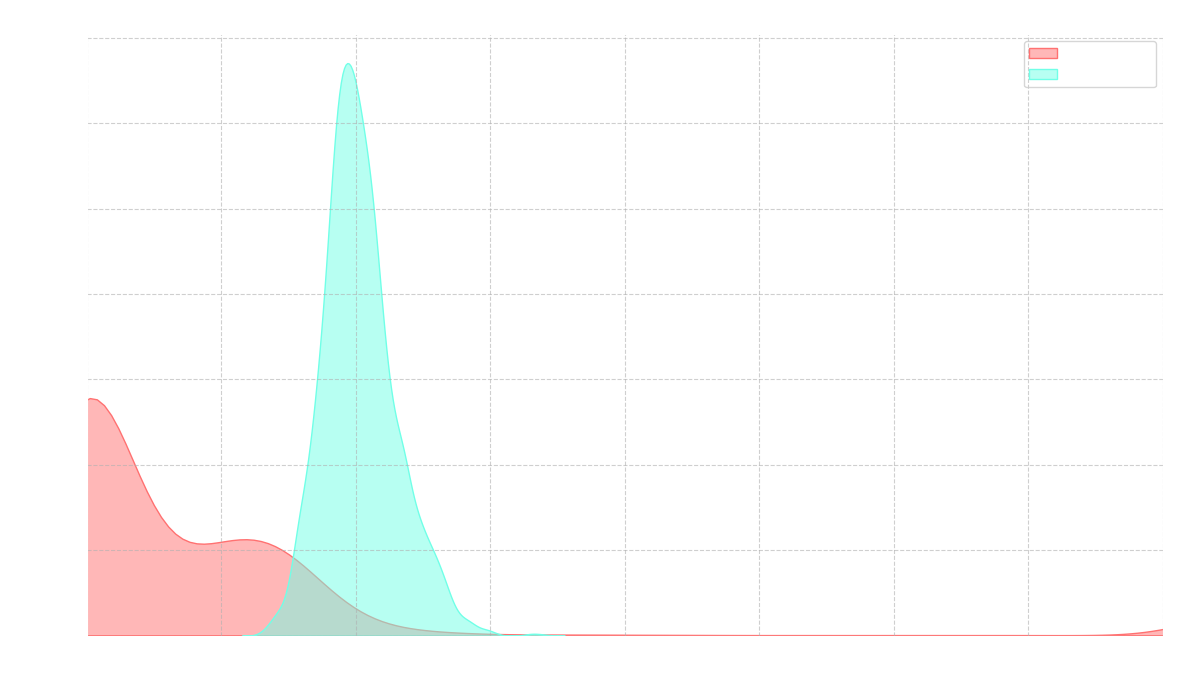

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))
sns.kdeplot(df['raw_length'], color='#FF7171', fill=True, alpha=0.5, label='교정 전 글자 수')
sns.kdeplot(df['corrected_length'], color='#71FFE7', fill=True, alpha=0.5, label='교정 후 글자 수')

plt.title('교정 전 대비 교정 후 본문 텍스트 분량 변화', fontsize=16)
plt.xlabel('글자 수', fontsize=12)
plt.ylabel('밀도', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlim(0, 4000)
plt.tight_layout()
plt.savefig('교정_전후_글자수_분포.png')
plt.show()

## 글자 수 차이 분포 시각화

### Subtask:
'diff' 컬럼(교정 후 - 교정 전 글자 수)의 분포를 히스토그램으로 시각화하여, 글자 수 변화의 크기와 방향(증가 또는 감소)을 명확하게 보여줍니다. 중앙값과 평균값을 함께 표시하여 해석을 돕습니다.

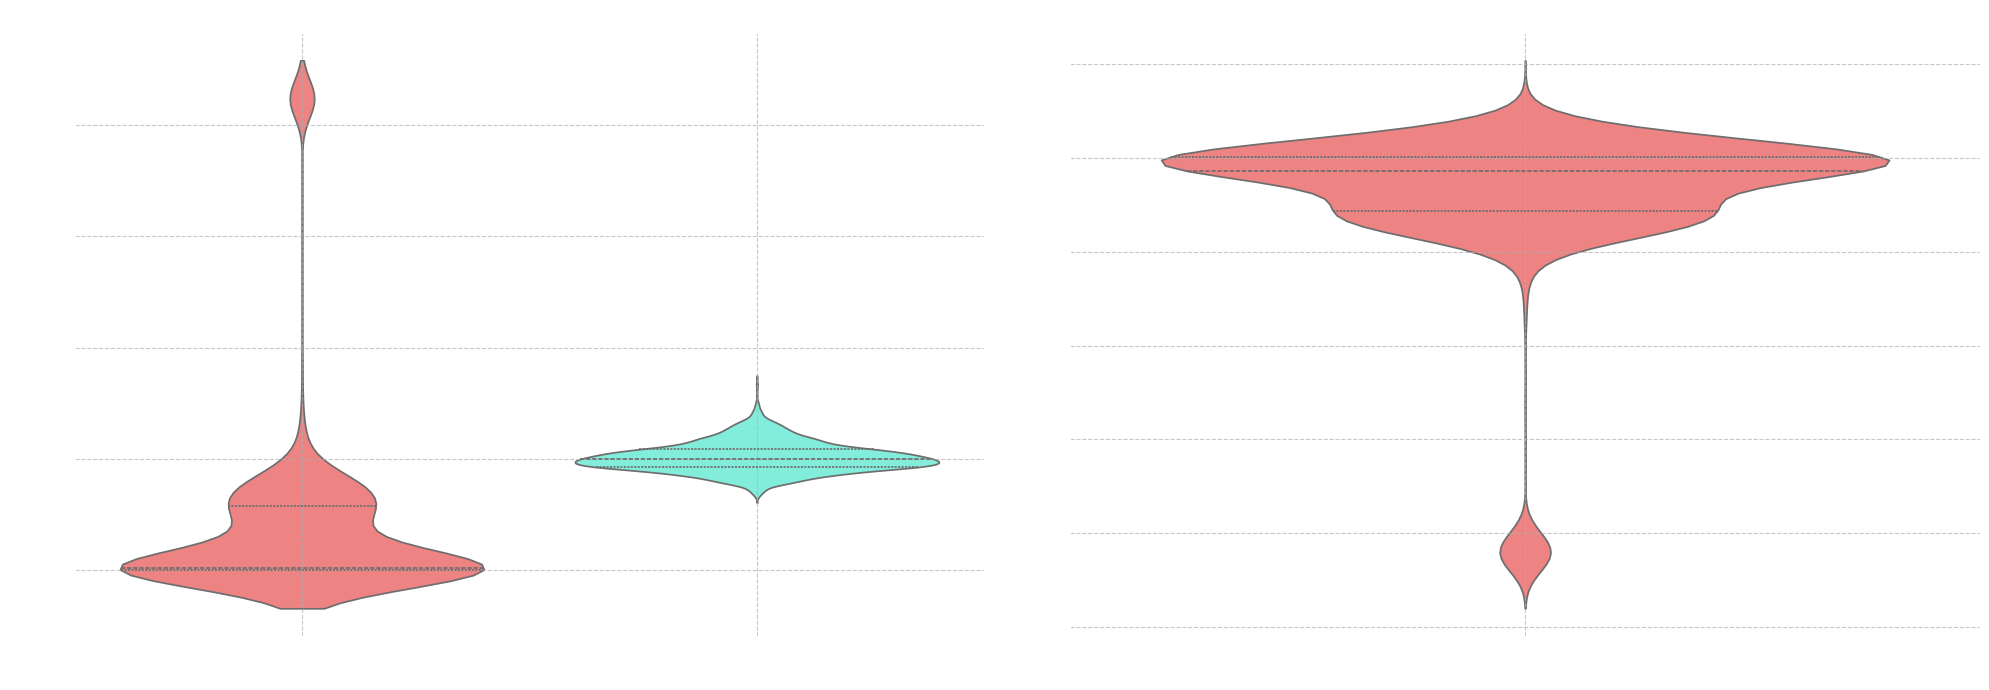

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

df_lengths = df[['raw_length', 'corrected_length']].melt(var_name='Length_Type', value_name='Length')
df_lengths['Length_Type'] = df_lengths['Length_Type'].map({
    'raw_length': '교정 전 글자 수',
    'corrected_length': '교정 후 글자 수'
})

fig, axes = plt.subplots(1, 2, figsize=(20, 7))

# 좌측 서브플롯: 교정 전/후 글자 수 분포
sns.violinplot(
    x='Length_Type',
    y='Length',
    data=df_lengths,
    hue='Length_Type',
    palette={'교정 전 글자 수': '#FF7171', '교정 후 글자 수': '#71FFE7'},
    inner='quartile',
    ax=axes[0],
    legend=False
)
axes[0].set_title('교정 전/후 글자 수 분포 (바이올린 플롯)', fontsize=14)
axes[0].set_xlabel('글자 수 유형', fontsize=12)
axes[0].set_ylabel('글자 수', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.7)

# 우측 서브플롯: 글자 수 변화량 (diff) 분포
sns.violinplot(
    y=df['diff'],
    color='#FF7171',
    inner='quartile',
    ax=axes[1]
)
axes[1].set_title('글자 수 변화량 (diff) 분포 (바이올린 플롯)', fontsize=14)
axes[1].set_xlabel('변화량', fontsize=12)
axes[1].set_ylabel('글자 수 변화량 (교정 후 - 교정 전)', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('글자수_분포_바이올린플롯.png')
plt.show()

## 데이터 행 번호에 따른 글자 수 차이 (diff) 2D 히스토그램

데이터 행 번호(DataFrame 인덱스)를 X축으로, 글자 수 차이('diff' 컬럼)를 Y축으로 하는 2D 히스토그램을 생성하여 데이터셋 전반에 걸친 글자 수 변화의 패턴을 시각적으로 탐색합니다.

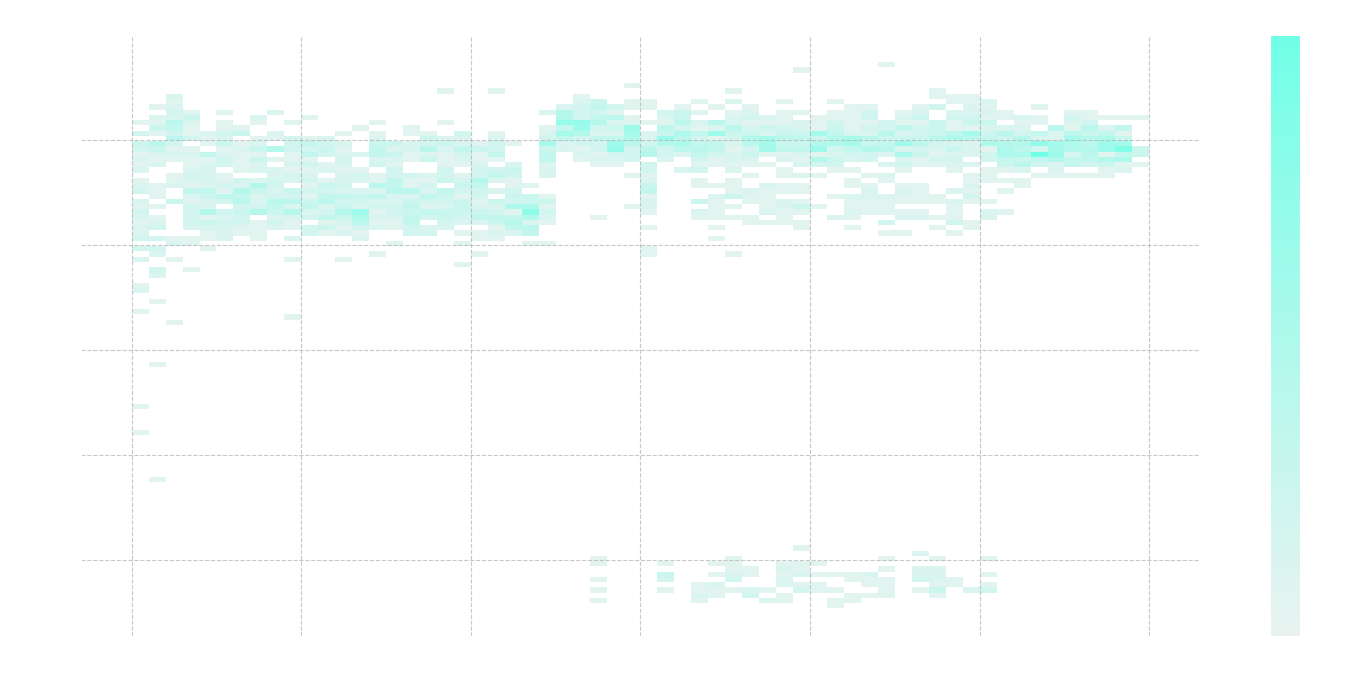

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(15, 7))
ax = sns.histplot(
    data=df,
    x=df.index,
    y='diff',
    binwidth=(50, 50),
    cmap=sns.light_palette("#71FFE7", as_cmap=True),
    cbar=True,
    cbar_kws={'label': '빈도수'}
)

plt.title('데이터 행 번호에 따른 글자 수 차이 (diff) 분포 (2D 히스토그램)', fontsize=16)
plt.xlabel('데이터 행 번호', fontsize=12)
plt.ylabel('글자 수 변화량 (교정 후 - 교정 전)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# 컬러바 레이블 및 틱 색상 설정
cbar = ax.collections[0].colorbar
cbar.set_label('빈도수', color='white')
cbar.ax.yaxis.set_tick_params(colors='white')

plt.tight_layout()
plt.savefig('글자수_차이_분포_2D_히스토그램.png')
plt.show()

## 글자 수 분포 바이올린 플롯

교정 전(`raw_length`), 교정 후(`corrected_length`) 글자 수와 글자 수 변화량(`diff`)의 분포를 바이올린 플롯으로 시각화합니다. 바이올린 플롯은 데이터의 밀도 추정치를 함께 보여주어 분포의 형태를 더욱 자세히 파악할 수 있게 합니다.

## 텍스트 길이 변화에 대한 종합 분석

이번 분석에서는 교정 전 텍스트(`raw_length`)와 교정 후 텍스트(`corrected_length`)의 길이에 유의미한 차이가 있는지 통계적 검정과 시각화 진행

#### 1. 통계적 검정 결과 (윌콕슨 부호순위 검정)

*   **정규성 검정 결과**: 차이값(`diff`)의 정규성 검정(D'Agostino's K-squared test, K-S test)에서 정규분포를 따르지 않음.(∵ 교정 전 텍스트 중 0자(빈값)의 비율이 32.3%로 높고, 차이값의 왜도(`skewness`)를 통해 비대칭성이 강함.) 이로 인해 모수 검정 대신 **비모수 검정인 윌콕슨 부호순위 검정(Wilcoxon Signed-Rank Test) 결과를 최종 판단 근거로 채택**

*   **윌콕슨 부호순위 검정 결과**: 윌콕슨 부호순위 검정 결과, 통계량 `Statistic: 363811.5000`에 `p-value: 0.0000e+00`. `p-value`가 유의수준 0.05보다 훨씬 작으므로 귀무가설(교정 전/후 글자 수 중앙값에 차이가 없다)을 기각. ⇒ **교정 전/후 텍스트 글자 수의 중앙값에 통계적으로 매우 유의미한 차이가 있음**

#### 3. 결론

**텍스트 교정 작업은 본문 텍스트의 길이를 통계적으로 유의미하게 증가**.  이는 교정 전 텍스트 중 글자 수가 매우 짧거나 아예 없던 경우가 많았음을 고려할 때, 교정 작업이 텍스트 내용을 **풍부하게 보완하는 역할** 수행
